In [1]:
import numpy as np
import scipy
import pandas as pd
import networkx as nx
import geopandas as gpd
import wntr

In [2]:
import os

os.chdir("/Users/vb/Desktop/MASTER_THESIS/MOO_OPT/NYT_validation")

print("Current working directory:", os.getcwd())

Current working directory: /Users/vb/Desktop/MASTER_THESIS/MOO_OPT/NYT_validation


In [3]:
from pymoo.core.problem import ElementwiseProblem
import numpy as np
import wntr


class NYNParallelProblem(ElementwiseProblem):

    def __init__(self, inp_file):

        self.inp_file = inp_file

        # ----------------------------------
        # Available rehabilitation options
        # ----------------------------------
        self.parallel_diameters_in = np.array([
            0,      # no parallel pipe
            36, 48, 60, 72, 84,
            96, 108, 120, 132,
            144, 156, 168, 180,
            192, 204
        ])

        # cost corresponding to options above
        self.cost_per_ft = np.array([
            0.0,    # no pipe
            93.5, 134, 176, 221, 267,
            316, 365, 417, 469,
            522, 577, 632, 689,
            746, 804
        ])

        # -----------------------------
        # Required heads (ft)
        # -----------------------------
        self.required_head_ft = {
            '2':255.0,
            '3':255.0,
            '4':255.0,
            '5':255.0,
            '6':255.0,
            '7':255.0,
            '8':255.0,
            '9':255.0,
            '10':255.0,
            '11':255.0,
            '12':255.0,
            '13':255.0,
            '14':255.0,
            '15':255.0,
            '16':260.0,
            '17':272.8,
            '18':255.0,
            '19':255.0,
            '20':255.0
        }

        self.required_head_m = {
            k: v * 0.3048
            for k, v in self.required_head_ft.items()
        }

        super().__init__(
            n_var=21,          # one variable per existing pipe
            n_obj=3,
            n_ieq_constr=19,
            xl=0,
            xu=15,
            vtype=int
        )

    def _evaluate(self, x, out, *args, **kwargs):

        wn = wntr.network.WaterNetworkModel(self.inp_file)

        total_cost = 0.0

        # ----------------------------------
        # Add rehabilitation pipes
        # ----------------------------------
        for pipe_name, option in zip(wn.pipe_name_list, x):

            option = int(round(option))
            option = np.clip(option, 0, 15)

            # 0 = no rehabilitation
            if option == 0:
                continue

            diameter_in = self.parallel_diameters_in[option]

            original_pipe = wn.get_link(pipe_name)

            parallel_name = f"{pipe_name}_parallel"

            wn.add_pipe(
                parallel_name,
                original_pipe.start_node_name,
                original_pipe.end_node_name,
                length=original_pipe.length,
                diameter=diameter_in * 0.0254,
                roughness=original_pipe.roughness
            )

            length_ft = original_pipe.length / 0.3048

            total_cost += (
                self.cost_per_ft[option]
                * length_ft
            )

        # ----------------------------------
        # Hydraulic simulation
        # ----------------------------------
        sim = wntr.sim.EpanetSimulator(wn)
        results = sim.run_sim()

        heads = results.node["head"].iloc[0]

        surplus_heads = []
        G = []

        for node_name, h_req in self.required_head_m.items():

            h_actual = heads[node_name]

            # constraint
            G.append(h_req - h_actual)

            # positive surplus only
            surplus = max(
                0.0,
                h_actual - h_req
            )

            surplus_heads.append(surplus)

        surplus_heads = np.array(surplus_heads)

        avg_surplus = np.mean(surplus_heads)

        variance_surplus = np.var(surplus_heads)

        out["F"] = [
            total_cost,
            avg_surplus,
            variance_surplus
        ]

        out["G"] = np.array(G)

In [5]:
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

from pymoo.operators.sampling.rnd import IntegerRandomSampling
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.repair.rounding import RoundingRepair

problem = NYNParallelProblem('/Users/vb/Desktop/MASTER_THESIS/Example_INP/nytun.inp.txt')
algorithm = NSGA2(
    pop_size=100,

    sampling=IntegerRandomSampling(),

    crossover=SBX(
        prob=0.9,
        eta=15,
        repair=RoundingRepair()
    ),

    mutation=PM(
        eta=20,
        repair=RoundingRepair()
    )
)

res = minimize(
    problem,
    algorithm,
    ('n_gen', 200),
    seed=1,
    verbose=True
)

n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |      100 |     24 |  0.000000E+00 |  1.244375E+01 |             - |             -
     2 |      200 |     31 |  0.000000E+00 |  0.000000E+00 |  0.0823486829 |         ideal
     3 |      300 |     34 |  0.000000E+00 |  0.000000E+00 |  0.0673689775 |         ideal
     4 |      400 |     52 |  0.000000E+00 |  0.000000E+00 |  0.0989309257 |         ideal
     5 |      500 |     69 |  0.000000E+00 |  0.000000E+00 |  0.0412931407 |         ideal
     6 |      600 |     81 |  0.000000E+00 |  0.000000E+00 |  0.0025160609 |         ideal
     7 |      700 |     82 |  0.000000E+00 |  0.000000E+00 |  0.0539159240 |         ideal
     8 |      800 |    100 |  0.000000E+00 |  0.000000E+00 |  0.0340093811 |         ideal
     9 |      900 |     99 |  0.000000E+00 |  0.000000E+00 |  0.0047126655 |         nadir
    10 |     1000 |    100 |  0.000000E+00 |  0.000000E+00 |  0.0130211218 |         ideal

In [6]:
print(np.min(res.F, axis=0))
print(np.max(res.F, axis=0))

[3.930e+07 5.998e+00 2.592e+00]
[1.890e+08 1.024e+01 1.330e+01]


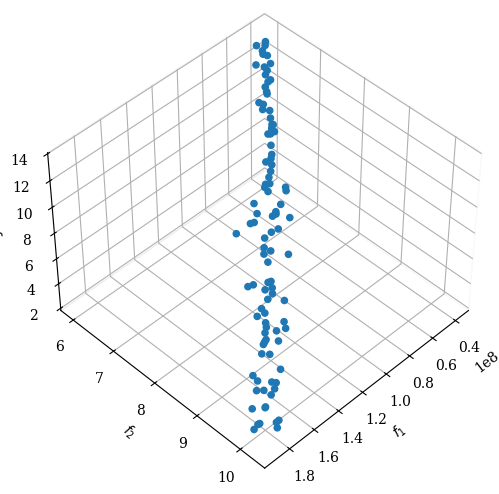

In [7]:
from pymoo.visualization.scatter import Scatter

Scatter().add(res.F).show()

In [ ]:
print(np.min(res.F, axis=0))
print(np.max(res.F, axis=0))
print(res.X[:5])

[3.930e+07 5.998e+00 2.592e+00]
[1.890e+08 1.024e+01 1.330e+01]
[[ 1 10  4  6 10 12 11 11  0  0  9 14 15 14 10 10 11 14 13  0 11]
 [ 0  0  0  0  0  0  8  2  0  0  0  0  0  0  0  6  6  5  4  0  4]
 [ 0  0  0  0  0  0  8  4  1  0  0  0  0  0  0  6  6  5  2  1  6]
 [ 1 10  2  8 11 13 10 11  0  0  8 15 14 14  7 11 14 14 13  0 15]
 [ 0  0  0  0  0  0 11  9  0  0  0  0  0  0  0  6  7  7  5  0  5]]


In [11]:
print(res.X[:9])

[[ 1 10  4  6 10 12 11 11  0  0  9 14 15 14 10 10 11 14 13  0 11]
 [ 0  0  0  0  0  0  8  2  0  0  0  0  0  0  0  6  6  5  4  0  4]
 [ 0  0  0  0  0  0  8  4  1  0  0  0  0  0  0  6  6  5  2  1  6]
 [ 1 10  2  8 11 13 10 11  0  0  8 15 14 14  7 11 14 14 13  0 15]
 [ 0  0  0  0  0  0 11  9  0  0  0  0  0  0  0  6  7  7  5  0  5]
 [ 0  0  0  4  0  0 11  8  0  0  0  0  0  0  0  6  9  7  6  0 10]
 [ 0  0  0  0  0  0  7  9  0  0  0  0  0  0  0  6  7  7  4  0  6]
 [ 0  0  1  0  0 11  9 10  0  0  0 13  0  0  0  6 10  7 10  0 12]
 [ 0  0  0  0  0  0  9  8  0  0  0 13  0  0  0  8 10  7  7  0 11]]
